# Classificação multirrótulo de imagens de fraturas ósseas
## Projeto de Ciência de Dados — Nível 3

Protótipo educacional: **sem validação clínica**, sem indicação para diagnóstico ou triagem.

## Resumo
**1.536 imagens rotuladas**, dez classes e 244 grupos de origem inferidos. No teste separado: **F1 macro 0.219**, **recall macro 0.396** e **acurácia de subconjunto 0.110**. Os resultados detalhados e limitações aparecem abaixo. Este desempenho experimental não valida uso clínico.
A tarefa é classificação por imagem. Não é detecção YOLO de caixas nem localização validada de fraturas.

## Contexto e método
O conjunto foi distribuído com anotações YOLOv8 para dez classes, incluindo `Healthy`.
Como há imagens com múltiplos rótulos, cada saída utiliza sigmoid independente e binary cross-entropy ponderada.
Não escolhemos arbitrariamente uma classe nem tratamos caixas como imagens independentes.

### Premissas
- As imagens já foram aumentadas na origem. Grupos de mesmo prefixo antes de `.rf.` ou pixels idênticos permanecem na mesma partição.
- Não há identificadores de paciente. Agrupamento por nome é conservador, mas pode juntar imagens distintas e não garante separação por paciente ou remoção de todas as imagens visualmente semelhantes.
- Três imagens sem rótulos são excluídas: ausência de anotação não é evidência de exame normal.
- O backbone MobileNetV2 usa pesos ImageNet e permanece congelado. Treinamos uma cabeça com Dense, L2, dropout, redução da taxa de aprendizado e early stopping.
- O balanceamento de perda e peso por grupo são calculados somente no treino. O limiar global é escolhido na validação; o teste não ajusta parâmetros.
- A resolução de entrada é reduzida de 640 para 160 pixels para execução em CPU; isso pode ocultar linhas sutis de fratura.

### Imagens locais e publicação
O `data.yaml` do arquivo identifica a licença como **Private**. As imagens originais, grids e mapas sobre imagens são mantidos localmente e ignorados pelo Git.
`01_fraturas_local.ipynb` contém as saídas visuais completas. A versão destinada ao GitHub remove apenas as saídas de células marcadas `private-images`; o código permanece e as imagens podem ser visualizadas ao executar localmente após obter o dataset.


In [1]:
from pathlib import Path
import sys,json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from IPython.display import display,Markdown
from sklearn.metrics import multilabel_confusion_matrix,f1_score,accuracy_score
ROOT=Path.cwd().resolve()
if not (ROOT/'preparar_dados.py').exists(): ROOT=ROOT.parent
sys.path.insert(0,str(ROOT))
from preparar_dados import CLASSES
sns.set_theme(style='whitegrid',palette='colorblind')
plt.rcParams.update({'figure.figsize':(10,5),'axes.titlesize':13,'savefig.dpi':150})
def savefig(name,private=False):
    folder=ROOT/'reports'/('private_figures' if private else 'figures')
    folder.mkdir(parents=True,exist_ok=True)
    plt.tight_layout(); plt.savefig(folder/f'{name}.png',bbox_inches='tight'); plt.show()


## Entrega 1 — Exploração e pré-processamento
### 1. Manifesto, anotações e auditoria
Execute `python preparar_dados.py` para baixar, extrair, validar os rótulos e reproduzir a divisão.
O arquivo de origem e seu hash estão em `reports/auditoria.json`.


images                                                                          1539
used_images                                                                     1536
empty_images_excluded                                                              3
multilabel_images                                                                113
groups                                                                           244
groups_crossing_original_splits                                                  100
exact_duplicate_excess                                                             0
annotation_issues                                                                  0
split_sizes                                {'train': 916, 'valid': 328, 'test': 292}
source                             https://cdn3.gnarususercontent.com.br/5327-che...
zip_sha256                         2245324d88560ee84eb5c90a0754447baffd0f77465eb1...
group_rule                         prefixo antes de .rf. OU hash 

,,imagens
width,height,
640,640,1539


,imagens,grupos
split,,
test,292,49
train,916,146
valid,328,49


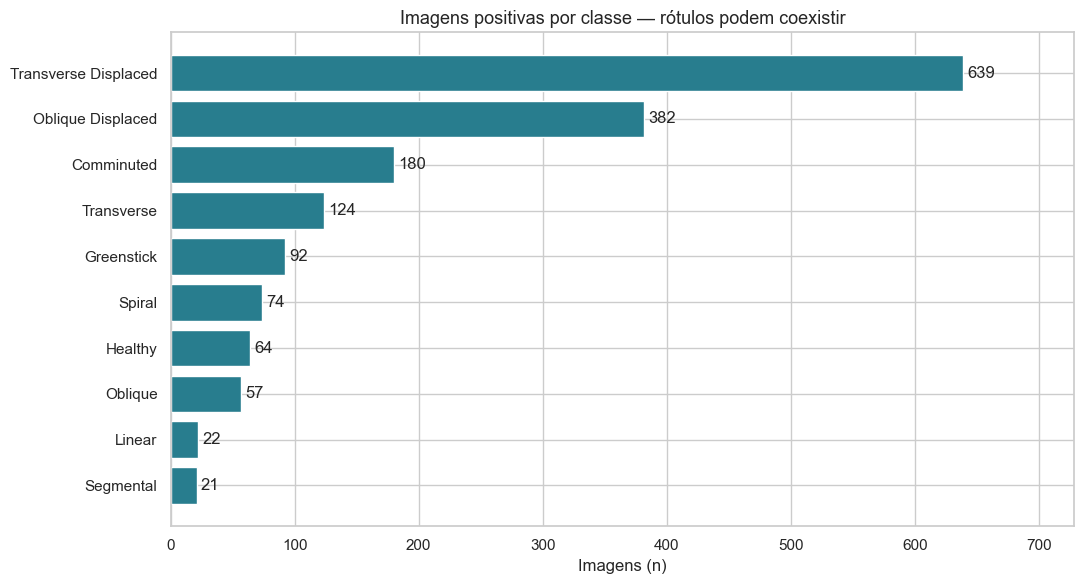

A classe mais comum é **Transverse Displaced** (639 imagens positivas); a menos comum é **Segmental** (21). As classes raras têm suporte baixo e métricas instáveis. A soma dos rótulos ultrapassa o número de imagens porque a tarefa é multirrótulo.

In [2]:
if not (ROOT/'data/manifest.csv').exists():
    from preparar_dados import prepare
    prepare()
manifest=pd.read_csv(ROOT/'data/manifest.csv')
frame=manifest[manifest.n_labels>0].copy()
annotations=pd.read_csv(ROOT/'data/annotations.csv')
audit=json.loads((ROOT/'reports/auditoria.json').read_text(encoding='utf-8'))
display(pd.Series(audit))
display(manifest[['width','height']].value_counts().to_frame('imagens'))
display(frame.groupby('split').agg(imagens=('image','size'),grupos=('group','nunique')))
counts=frame[CLASSES].sum().sort_values()
fig,ax=plt.subplots(figsize=(11,6))
ax.barh(counts.index,counts.values,color='#287D8E'); ax.bar_label(ax.containers[0],padding=3)
ax.set(title='Imagens positivas por classe — rótulos podem coexistir',xlabel='Imagens (n)',xlim=(0,counts.max()*1.14))
savefig('01_classes')
display(Markdown(f'A classe mais comum é **{counts.idxmax()}** ({counts.max()} imagens positivas); '
                 f'a menos comum é **{counts.idxmin()}** ({counts.min()}). '
                 'As classes raras têm suporte baixo e métricas instáveis. A soma dos rótulos ultrapassa o número de imagens porque a tarefa é multirrótulo.'))


### 2. Exemplos por classe — visualização local
As caixas verdes são anotações fornecidas, não previsões. Rótulos distintos podem coexistir na mesma imagem.
Os exemplos são selecionados deterministicamente por nome, sem escolher apenas imagens visualmente fáceis.
Na inspeção visual, há exemplos coloridos com aparência ilustrativa, além de imagens em escala de cinza. O domínio é heterogêneo; não presumimos que todo registro seja uma radiografia clínica autêntica.


In [3]:
import matplotlib.patches as patches
fig,axes=plt.subplots(2,5,figsize=(17,8))
for idx,(ax,c) in enumerate(zip(axes.flat,CLASSES)):
    row=frame.loc[frame[c]==1].sort_values('image').iloc[0]
    image=np.asarray(Image.open(ROOT/row.path).convert('RGB'))
    ax.imshow(image)
    for box in annotations.loc[(annotations.image==row.image)&(annotations.class_id==idx)].itertuples():
        h,w=image.shape[:2]
        ax.add_patch(patches.Rectangle(((box.x-box.w/2)*w,(box.y-box.h/2)*h),box.w*w,box.h*h,
                                       fill=False,edgecolor='lime',linewidth=1.2))
    ax.set_title(c); ax.axis('off')
savefig('02_exemplos_classes',private=True)


### 3. Coocorrência e divisão por grupos
Os nomes de origem repetidos entre partições motivam reconstruir a divisão em vez de confiar nos diretórios originais.
A procura determinística de uma divisão equilibrada utiliza apenas rótulos e grupos, sem resultados de modelos.


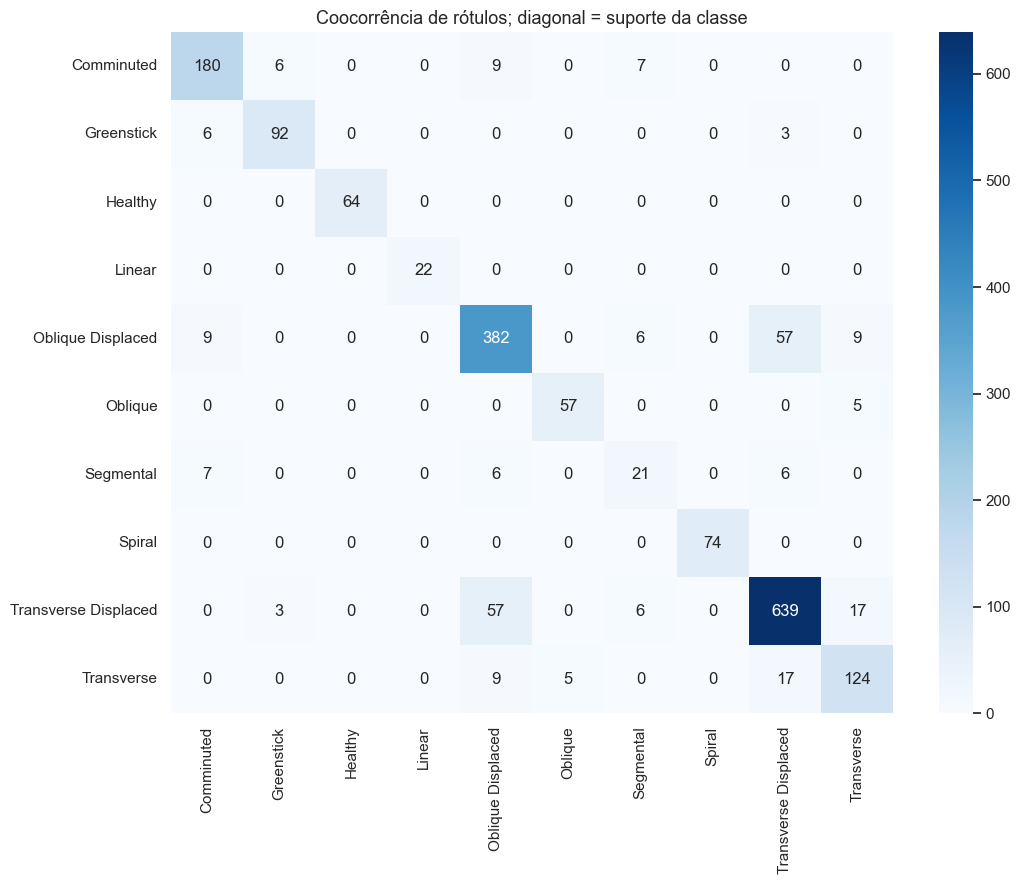

,Comminuted,Greenstick,Healthy,Linear,Oblique Displaced,Oblique,Segmental,Spiral,Transverse Displaced,Transverse
split,,,,,,,,,,
train,103,50,37,9,221,35,11,39,410,62
valid,32,19,16,3,81,9,7,21,151,28
test,45,23,11,10,80,13,3,14,78,34


,Comminuted,Greenstick,Healthy,Linear,Oblique Displaced,Oblique,Segmental,Spiral,Transverse Displaced,Transverse
split,,,,,,,,,,
train,35,7,6,2,36,6,2,6,62,11
valid,8,3,2,1,12,1,1,4,26,4
test,14,4,2,2,13,2,1,2,15,5


Verificado: nenhum grupo inferido e nenhum hash de pixels cruza as novas partições.


**Desafios:** classes visualmente próximas, poucas origens em classes raras, imagens previamente aumentadas, resolução reduzida e ausência de IDs de paciente. Os limites de métricas por imagem não devem ser confundidos com evidência clínica.

In [4]:
co=frame[CLASSES].to_numpy().T@frame[CLASSES].to_numpy()
fig,ax=plt.subplots(figsize=(11,9))
sns.heatmap(co,annot=True,fmt='d',xticklabels=CLASSES,yticklabels=CLASSES,cmap='Blues',ax=ax)
ax.set_title('Coocorrência de rótulos; diagonal = suporte da classe')
savefig('03_coocorrencia')
dist=frame.groupby('split')[CLASSES].sum().reindex(['train','valid','test'])
display(dist)
group_support=frame.groupby(['split','group'])[CLASSES].max().groupby('split').sum().reindex(['train','valid','test'])
display(group_support)
group_support.to_csv(ROOT/'reports/grupos_por_classe.csv')
assert frame.groupby('group').split.nunique().max()==1
assert frame.groupby('pixel_hash').split.nunique().max()==1
print('Verificado: nenhum grupo inferido e nenhum hash de pixels cruza as novas partições.')
display(Markdown('**Desafios:** classes visualmente próximas, poucas origens em classes raras, imagens previamente aumentadas, '
                 'resolução reduzida e ausência de IDs de paciente. Os limites de métricas por imagem não devem ser confundidos com evidência clínica.'))


### 4. Pré-processamento
OpenCV decodifica a imagem, redimensiona para 160×160 e converte BGR para RGB. O modelo exportado recebe RGB em 0–255 e incorpora a normalização para −1 a 1 exigida pelo MobileNetV2.
No treino acrescentamos uma versão com rotação de até 3 graus e brilho de ±5%; não aumentamos validação ou teste. Como a origem já contém aumentos, essa transformação é leve.
As caixas são usadas para auditoria e visualização; a classificação utiliza a imagem inteira. Grad-CAM não substitui um detector.


## Entrega 2 — Construção e avaliação
### 5. Treinamento reproduzível
`treino.py` contém o treinamento completo. O backbone congelado extrai atributos das imagens originais e das versões aumentadas de treino; a cabeça usa dropout e regularização L2.
Pesos positivos por classe são limitados a 12; pesos por imagem evitam que grupos com muitas versões dominem a perda.
Early stopping monitora a perda de validação, com paciência 7 e restauração do melhor estado. A taxa de aprendizado é reduzida quando a validação estagna.
O backbone pré-treinado e o modelo ajustado são um único pipeline exportado em `.keras`.


architecture           MobileNetV2 ImageNet congelada + Dense128 L2 +...
image_size                                                           160
threshold                                                            0.4
epochs_executed                                                        8
best_epoch_val_loss                                                    1
dtype: object

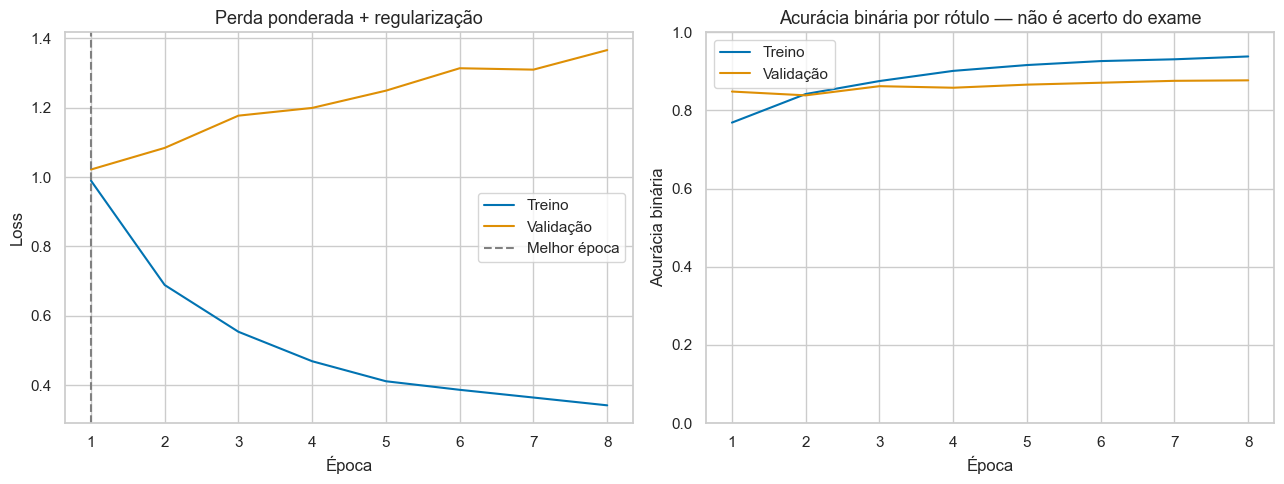

A perda de treino usa amostras aumentadas e ponderação por grupo; a de validação não. Portanto, suas magnitudes não são diretamente comparáveis como um teste isolado de overfitting. A acurácia binária pode parecer alta devido à quantidade de rótulos negativos; priorizamos F1 macro e recall por classe.

In [5]:
if not (ROOT/'models/metadata.json').exists():
    import subprocess
    subprocess.run([sys.executable,'treino.py','--epochs','60'],cwd=ROOT,check=True)
meta=json.loads((ROOT/'models/metadata.json').read_text(encoding='utf-8'))
history=pd.read_csv(ROOT/'reports/history.csv')
display(pd.Series({k:meta[k] for k in ['architecture','image_size','threshold','epochs_executed','best_epoch_val_loss']}))
fig,axes=plt.subplots(1,2,figsize=(13,5))
epochs=np.arange(1,len(history)+1)
axes[0].plot(epochs,history.loss,label='Treino'); axes[0].plot(epochs,history.val_loss,label='Validação')
axes[0].axvline(meta['best_epoch_val_loss'],color='gray',linestyle='--',label='Melhor época')
axes[0].set(title='Perda ponderada + regularização',xlabel='Época',ylabel='Loss'); axes[0].legend()
axes[1].plot(epochs,history.binary_accuracy,label='Treino'); axes[1].plot(epochs,history.val_binary_accuracy,label='Validação')
axes[1].set(title='Acurácia binária por rótulo — não é acerto do exame',xlabel='Época',ylabel='Acurácia binária',ylim=(0,1)); axes[1].legend()
savefig('04_curvas_aprendizado')
display(Markdown('A perda de treino usa amostras aumentadas e ponderação por grupo; a de validação não. '
                 'Portanto, suas magnitudes não são diretamente comparáveis como um teste isolado de overfitting. '
                 'A acurácia binária pode parecer alta devido à quantidade de rótulos negativos; priorizamos F1 macro e recall por classe.'))


### 6. Métricas e referência simples
**Subset accuracy** conta apenas imagens em que todos os rótulos foram previstos corretamente.
F1 macro dá o mesmo peso às classes; F1 micro agrega decisões; average precision mede ordenação de escores e não exige limiar fixo.
A referência prevê em todas as imagens a classe mais prevalente no treino. Assim, não usamos uma referência vazia que prevê ausência de todos os rótulos.
O limiar global é escolhido entre 0,15 e 0,80 na validação. Não se ajusta um limiar separado para cada classe rara.


In [6]:
metrics=pd.DataFrame(meta['metrics']).T
display(metrics.round(4))
display(Markdown('**Resultado limitado:** o teste tem F1 macro baixo e classes sem verdadeiros positivos previstos. '
                 'O desempenho superior no treino indica sobreajuste e dificuldade de generalização entre grupos. '
                 'Nenhuma métrica aqui sustenta uso médico.'))
report=pd.read_csv(ROOT/'reports/classificacao_test.csv',index_col=0)
display(report.round(3))
test=pd.read_csv(ROOT/'reports/previsoes_test.csv')
truth=test[[f'true_{c}' for c in CLASSES]].to_numpy()
pred=test[[f'pred_{c}' for c in CLASSES]].to_numpy()
assert np.isclose(f1_score(truth,pred,average='macro',zero_division=0),meta['metrics']['test']['f1_macro'])
interval=meta['test_f1_macro_group_bootstrap_95pct']
display(Markdown(f'F1 macro no teste: **{meta["metrics"]["test"]["f1_macro"]:.3f}**; '
                 f'intervalo bootstrap por grupo de origem: **[{interval[0]:.3f}; {interval[1]:.3f}]**. '
                 'É um intervalo exploratório condicionado a este modelo e estes grupos inferidos; classes podem faltar em reamostragens e recebem F1 zero. '
                 'Não inclui toda a incerteza do treino ou de uma população real.'))


,n_images,n_groups,subset_accuracy,f1_macro,f1_micro,precision_macro,recall_macro,hamming_loss,average_precision_macro,baseline_f1_macro,baseline_subset_accuracy
train,916.0,146.0,0.1452,0.5009,0.5067,0.4268,0.7938,0.1737,0.6825,0.0618,0.4028
valid,328.0,49.0,0.0884,0.2672,0.3980,0.1969,0.5123,0.2186,0.3181,0.0630,0.3902
test,292.0,49.0,0.1096,0.2191,0.3006,0.1572,0.3957,0.2438,0.2167,0.0422,0.2226


**Resultado limitado:** o teste tem F1 macro baixo e classes sem verdadeiros positivos previstos. O desempenho superior no treino indica sobreajuste e dificuldade de generalização entre grupos. Nenhuma métrica aqui sustenta uso médico.

,precision,recall,f1-score,support
Comminuted,0.303,0.667,0.417,45.0
Greenstick,0.105,0.478,0.172,23.0
Healthy,0.135,0.455,0.208,11.0
Linear,0.000,0.000,0.000,10.0
Oblique Displaced,0.328,0.500,0.396,80.0
Oblique,0.057,0.308,0.096,13.0
Segmental,0.000,0.000,0.000,3.0
Spiral,0.171,0.500,0.255,14.0
Transverse Displaced,0.254,0.462,0.327,78.0
Transverse,0.220,0.588,0.320,34.0


F1 macro no teste: **0.219**; intervalo bootstrap por grupo de origem: **[0.160; 0.262]**. É um intervalo exploratório condicionado a este modelo e estes grupos inferidos; classes podem faltar em reamostragens e recebem F1 zero. Não inclui toda a incerteza do treino ou de uma população real.

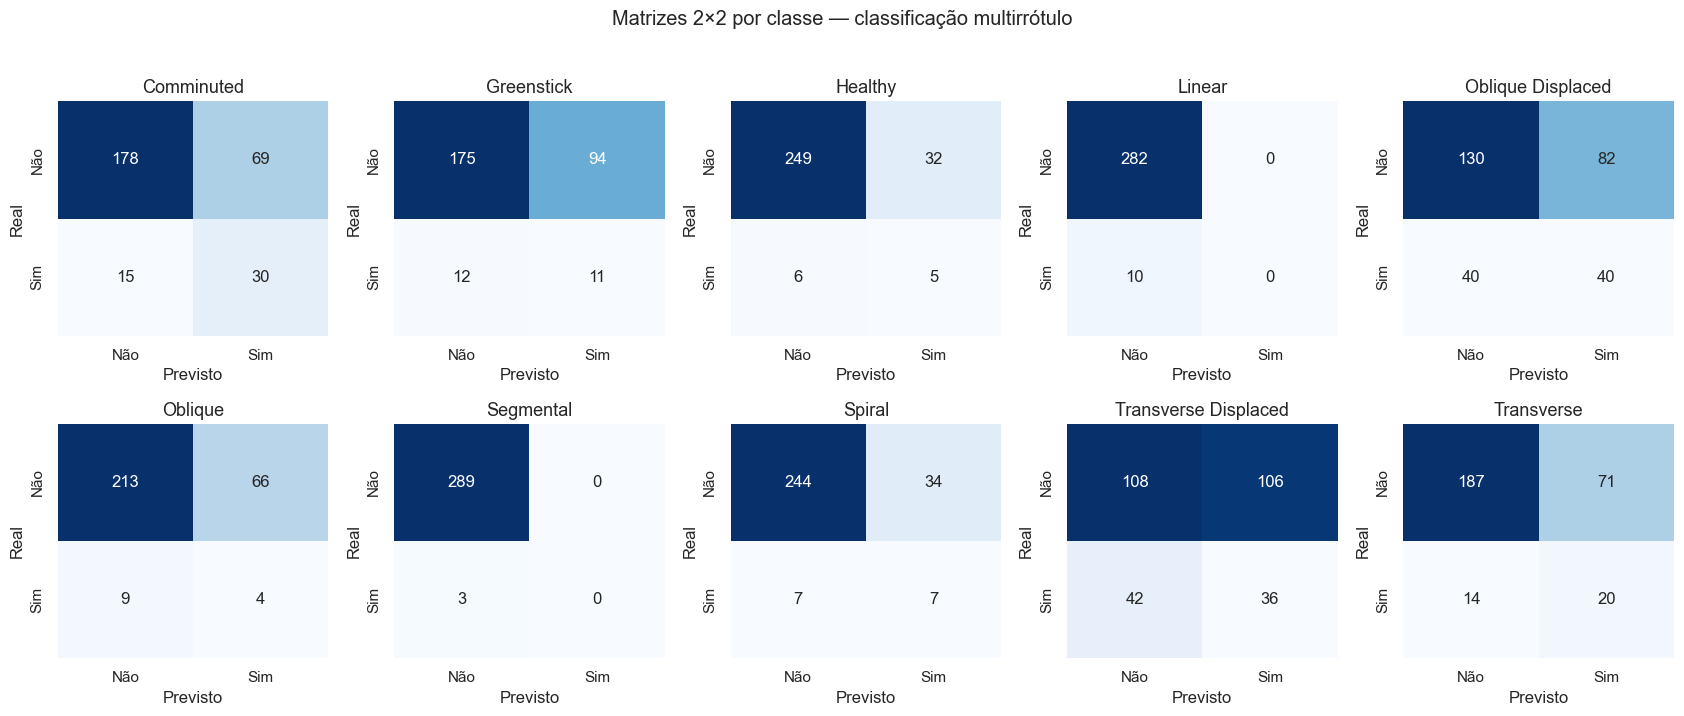

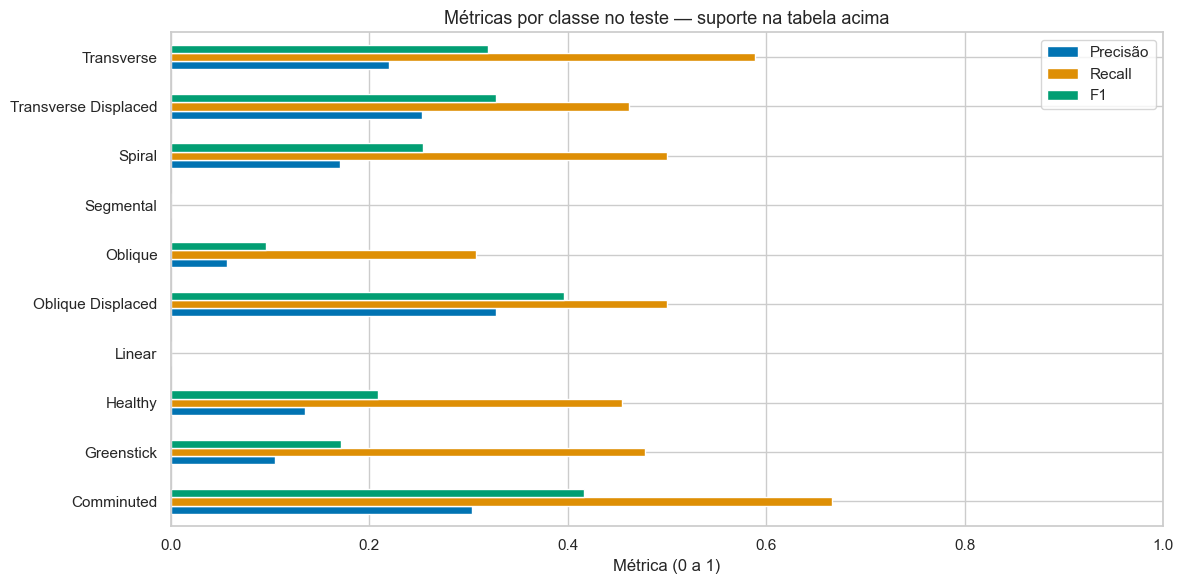

In [7]:
cms=multilabel_confusion_matrix(truth,pred)
fig,axes=plt.subplots(2,5,figsize=(17,7))
for ax,c,cm in zip(axes.flat,CLASSES,cms):
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=ax,xticklabels=['Não','Sim'],yticklabels=['Não','Sim'])
    ax.set(title=c,xlabel='Previsto',ylabel='Real')
fig.suptitle('Matrizes 2×2 por classe — classificação multirrótulo',y=1.02)
savefig('05_matrizes_confusao')
fig,ax=plt.subplots(figsize=(12,6))
report.loc[CLASSES,['precision','recall','f1-score']].plot.barh(ax=ax)
ax.set(title='Métricas por classe no teste — suporte na tabela acima',xlabel='Métrica (0 a 1)',xlim=(0,1),ylabel='')
ax.legend(['Precisão','Recall','F1']); savefig('06_metricas_classes')


### 7. Interpretabilidade — Grad-CAM local
Usamos gradientes do escore da classe prevista sobre os mapas convolucionais finais do backbone, seguindo o método descrito no [exemplo oficial do Keras](https://keras.io/examples/vision/grad_cam/).
Selecionamos três casos com maior e três com menor F1 por imagem no teste, sem omitir erros. Isso é uma seleção para inspeção qualitativa, não uma nova avaliação independente.
As caixas verdes mostram apenas anotações da classe visualizada, quando ela está presente. O mapa pode se concentrar em texto, marcadores ou fundo; não comprova localização de lesão.


In [8]:
from predicao import load_artifacts,predict_image,overlay_gradcam
model,loaded_meta=load_artifacts()
tp=(truth*pred).sum(axis=1)
denom=truth.sum(axis=1)+pred.sum(axis=1)
sample_f1=2*tp/np.maximum(denom,1)
chosen=[]; seen_groups=set()
for ordering in [np.argsort(-sample_f1),np.argsort(sample_f1)]:
    added=0
    for index in ordering:
        group=test.iloc[index].group
        if group in seen_groups: continue
        chosen.append(int(index)); seen_groups.add(group); added+=1
        if added==3: break
fig,axes=plt.subplots(2,3,figsize=(13,9))
findings=[]
for ax,i in zip(axes.flat,chosen):
    row=test.iloc[i]
    with Image.open(ROOT/row.path) as im:
        result,array=predict_image(im,model,loaded_meta)
    top=max(range(len(result)),key=lambda j:result[j]['escore'])
    overlay,heat=overlay_gradcam(model,array,top)
    ax.imshow(overlay)
    for box in annotations.loc[(annotations.image==row.image)&(annotations.class_id==top)].itertuples():
        size=meta['image_size']
        ax.add_patch(patches.Rectangle(((box.x-box.w/2)*size,(box.y-box.h/2)*size),box.w*size,box.h*size,
                                      fill=False,edgecolor='lime',linewidth=1))
    ax.set_title(f'{CLASSES[top]} | escore {result[top]["escore"]:.2f}\nF1 da imagem {sample_f1[i]:.2f}',fontsize=10); ax.axis('off')
    findings.append({'image':row.image,'class_visualized':CLASSES[top],'image_f1':float(sample_f1[i]),
                     'heat_nonzero':bool(heat.max()>0),'class_in_ground_truth':bool(truth[i,top]),
                     'heat_mean':float(heat.mean())})
savefig('07_gradcam_casos',private=True)
pd.DataFrame(findings).to_csv(ROOT/'reports/gradcam_casos.csv',index=False)
display(pd.DataFrame(findings))


### Descobertas de interpretabilidade
O Grad-CAM destaca regiões em uma grade espacial baixa (5×5 antes da ampliação), portanto o mapa é grosseiro e pode cobrir áreas amplas.
Os exemplos incluem previsões corretas e incorretas; uma região destacada não torna uma previsão confiável. As classes visualizadas e a presença do rótulo no gabarito ficam em `reports/gradcam_casos.csv`.
Os mapas observados são amplos e nem sempre coincidem com as caixas fornecidas. Há também imagens coloridas de aparência ilustrativa entre os casos selecionados, reforçando a necessidade de revisar a procedência e a composição do dataset.
Não calculamos métricas de detecção: os mapas de atenção não são bounding boxes previstas.


## Entrega 3 — Aplicação e boas práticas
### Aplicação local
Na raiz: `python -m streamlit run app.py`.
O aplicativo permite carregar JPG/PNG, exibir os dez escores e solicitar Grad-CAM para uma classe. Não envia a imagem a serviços externos e não a salva.
O processamento ocorre no servidor da aplicação: se você hospedar remotamente, o upload irá para esse servidor. Este projeto não publica o aplicativo na internet.
O modelo não verifica se a imagem é um raio-X nem reconhece automaticamente entradas fora do domínio.

### Pipeline
1. `preparar_dados.py`: download, extração segura, validação YOLO, manifesto e divisão agrupada.
2. `treino.py`: pré-processamento, extração congelada, aumento leve no treino, cabeça regularizada, limiar e avaliação.
3. `predicao.py`: carrega o modelo sem compilar a perda de treino e aplica exatamente o pré-processamento exportado.
4. `app.py`: interface local e explicação visual por Grad-CAM.
5. `validate_project.py`: verificações de partições, métricas, modelo recarregado, Grad-CAM e aplicação.

## Recomendações e limitações
- Este protótipo não está apto a apoiar decisões médicas. As métricas devem ser avaliadas por classe e com atenção ao suporte de poucas origens.
- Obter IDs de pacientes e estudo, revisar anotações com profissionais qualificados e construir uma avaliação externa com separação por paciente antes de considerar outro uso.
- Não interpretar `Healthy`, ausência de rótulos acima do limiar ou escore baixo como exclusão de fratura.
- Não usar mapas Grad-CAM como evidência de localização correta de uma lesão. Revisar possível atenção a marcadores, bordas e texto.
- Classes raras precisam de mais imagens de origem; versões aumentadas não substituem novos pacientes ou estudos independentes.
- A rede ImageNet foi treinada em imagens naturais; transferência de domínio, redução de resolução e aumentos podem limitar desempenho em radiografias.
- Não há calibração clínica, avaliação prospectiva, validação regulatória ou garantia de representatividade do hospital.


In [9]:
t=meta['metrics']['test']
resumo=(f'# Resultados — classificação multirrótulo de fraturas\n\n'
        f'{audit["images"]} imagens; {audit["used_images"]} utilizadas; {audit["multilabel_images"]} multirrótulo. '
        f'{audit["groups"]} grupos inferidos; {audit["groups_crossing_original_splits"]} cruzavam as partições originais.\n\n'
        f'## Modelo e avaliação\n{meta["architecture"]}. Limiar escolhido na validação: {meta["threshold"]:.2f}. '
        f'{meta["epochs_executed"]} épocas executadas; melhor época por val_loss: {meta["best_epoch_val_loss"]}.\n'
        f'- Teste: {t["n_images"]} imagens de {t["n_groups"]} grupos inferidos.\n'
        f'- Subset accuracy: {t["subset_accuracy"]:.4f}.\n'
        f'- Precisão macro: {t["precision_macro"]:.4f}; recall macro: {t["recall_macro"]:.4f}.\n'
        f'- F1 macro: {t["f1_macro"]:.4f}; F1 micro: {t["f1_micro"]:.4f}.\n'
        f'- F1 macro da referência constante: {t["baseline_f1_macro"]:.4f}.\n\n'
        'Acurácia significa coincidência exata do conjunto de rótulos, não acerto clínico de diagnóstico. '
        'Há classes raras com poucas origens e os grupos não são IDs de pacientes. '
        'Sem validação clínica; não utilizar para diagnóstico, triagem ou tratamento.\n')
(ROOT/'reports/resultados.md').write_text(resumo,encoding='utf-8')
display(Markdown(resumo))


# Resultados — classificação multirrótulo de fraturas

1539 imagens; 1536 utilizadas; 113 multirrótulo. 244 grupos inferidos; 100 cruzavam as partições originais.

## Modelo e avaliação
MobileNetV2 ImageNet congelada + Dense128 L2 + Dropout0.45 + sigmoid10. Limiar escolhido na validação: 0.40. 8 épocas executadas; melhor época por val_loss: 1.
- Teste: 292 imagens de 49 grupos inferidos.
- Subset accuracy: 0.1096.
- Precisão macro: 0.1572; recall macro: 0.3957.
- F1 macro: 0.2191; F1 micro: 0.3006.
- F1 macro da referência constante: 0.0422.

Acurácia significa coincidência exata do conjunto de rótulos, não acerto clínico de diagnóstico. Há classes raras com poucas origens e os grupos não são IDs de pacientes. Sem validação clínica; não utilizar para diagnóstico, triagem ou tratamento.
